# Option 3 Alignment QC

## Mapping, geometry, T1–DWI registration, and sampling validity

This is a summary-only notebook. It reads tables and surface/volume figures produced by the standalone Option 3 QC script, performs lightweight plot-oriented summaries, and contains the cohort-level visualization code. It does not load subject surfaces or profiles, recompute subject-level QC metrics, resample MD, or modify production outputs.

Depth convention: **pial (0) to white (1), 21 points**.
The analysis mask is the fixed fsaverage cortex intersected with valid DK labels. Cohort summaries use the subject as the independent unit and report median [IQR] and range. Failed or missing subjects remain explicit.

## Reproducible calculation command

Run the calculation-heavy step on a compute node from the repository root:

```bash
python -u qc/option3/scripts/run_option3_alignment_qc.py
```

The default output is `/mnt/newStor/paros/paros_WORK/xintong/results/qc/full_cohort_spatial_scale/option3_alignment_qc_v2`. Optional arguments are `--manifest`, `--subjects-dir`, `--output-dir`, and `--covariates`. Use `--limit 1 --output-dir /tmp/option3_qc_check` for a single-subject validation run. The corresponding Slurm launcher is `qc/option3/slurm/run_option3_alignment_qc.sbatch`.

In [1]:
from pathlib import Path
import json
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, Markdown, display

REPO_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / 'qc/publication_style.py').is_file()
)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from qc.publication_style import PALETTE, set_publication_style, style_axes

RESULTS_ROOT = Path('/mnt/newStor/paros/paros_WORK/xintong/results')
OUTPUT_ROOT = RESULTS_ROOT / 'qc/full_cohort_spatial_scale/option3_alignment_qc_v2'
TABLE_ROOT = OUTPUT_ROOT / 'tables'
FIGURE_ROOT = OUTPUT_ROOT / 'figures'
NOTEBOOK_FIGURE_ROOT = OUTPUT_ROOT / 'notebook_figures'
METADATA_PATH = OUTPUT_ROOT / 'run_metadata.json'
READY = METADATA_PATH.is_file()

set_publication_style()
sns.set_theme(style='ticks', context='paper')

if READY:
    metadata = json.loads(METADATA_PATH.read_text())
    NOTEBOOK_FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
    display(metadata)
else:
    metadata = {'status': 'pending', 'figures': []}
    display(Markdown(
        f'**Option 3 Alignment QC status:** external calculation pending.  '
        f'Expected completion record: `{METADATA_PATH}`'
    ))

def read_table(name, **kwargs):
    return pd.read_csv(TABLE_ROOT / name, **kwargs)

def table(name, **kwargs):
    path = TABLE_ROOT / name
    if path.is_file():
        display(pd.read_csv(path, **kwargs))
    else:
        display(Markdown(f'*Pending table:* `{path}`'))

def show_figure(name):
    path = FIGURE_ROOT / f'{name}.png'
    if path.is_file():
        display(Image(filename=str(path)))
    else:
        display(Markdown(f'*Pending figure:* `{path}`'))

def save_figure(figure, name):
    if READY:
        png_path = NOTEBOOK_FIGURE_ROOT / f'{name}.png'
        pdf_path = NOTEBOOK_FIGURE_ROOT / f'{name}.pdf'
        figure.savefig(
            png_path, dpi=300,
            bbox_inches='tight',
        )
        figure.savefig(
            pdf_path,
            bbox_inches='tight',
        )
        plt.close(figure)
        display(Image(filename=str(png_path)))

if READY:
    status = read_table('status.csv', dtype={'subject_id': str})
    subject_qc = read_table('subject_qc.csv', dtype={'subject_id': str})
    hemisphere_qc = read_table('hemisphere_qc.csv', dtype={'subject_id': str})
    depth_qc = read_table('depth_qc.csv', dtype={'subject_id': str})
    registration_qc = read_table('registration_qc.csv', dtype={'subject_id': str})
    label_qc = read_table('label_qc.csv', dtype={'subject_id': str})

{'status': 'complete',
 'source_mode': 'completed_option3_cohort_cache',
 'source_directory': '/mnt/newStor/paros/paros_WORK/xintong/results/qc/full_cohort_spatial_scale/option3_qc/cohort',
 'n_requested': 327,
 'n_successful': 325,
 'n_failed': 2,
 'coverage_review_pct': 95.0,
 'table_directory': '/mnt/newStor/paros/paros_WORK/xintong/results/qc/full_cohort_spatial_scale/option3_alignment_qc_v2/tables',
 'figure_directory': '/mnt/newStor/paros/paros_WORK/xintong/results/qc/full_cohort_spatial_scale/option3_alignment_qc_v2/figures',
 'figures': [],
 'limitations': ['The completed cohort cache does not contain the union of point-level invalid events within the analysis mask; point_invalid_pct is left missing.',
  'Depth-specific point rates use the denominators stored by the completed cohort cache.',
  'Bilateral length-thickness statistics are mask-size-weighted hemisphere summaries rather than correlations refit after pooling vertices.',
  'Equal-spacing error was not retained in the 

## Cohort completeness
The manifest determines the requested cohort size. Failed subjects remain visible and do not count as passing QC. Bilateral summaries require both hemispheres to succeed.

,status,n_subjects
0,complete,325
1,failed,2


,subject_id,status,reason
0,D0007,complete,NaN
1,D0029,complete,NaN
2,D0049,complete,NaN
3,D0050,complete,NaN
4,D0051,complete,NaN
...,...,...,...
322,D0443,complete,NaN
323,D0445,complete,NaN
324,D0449,complete,NaN
325,D0454,complete,NaN


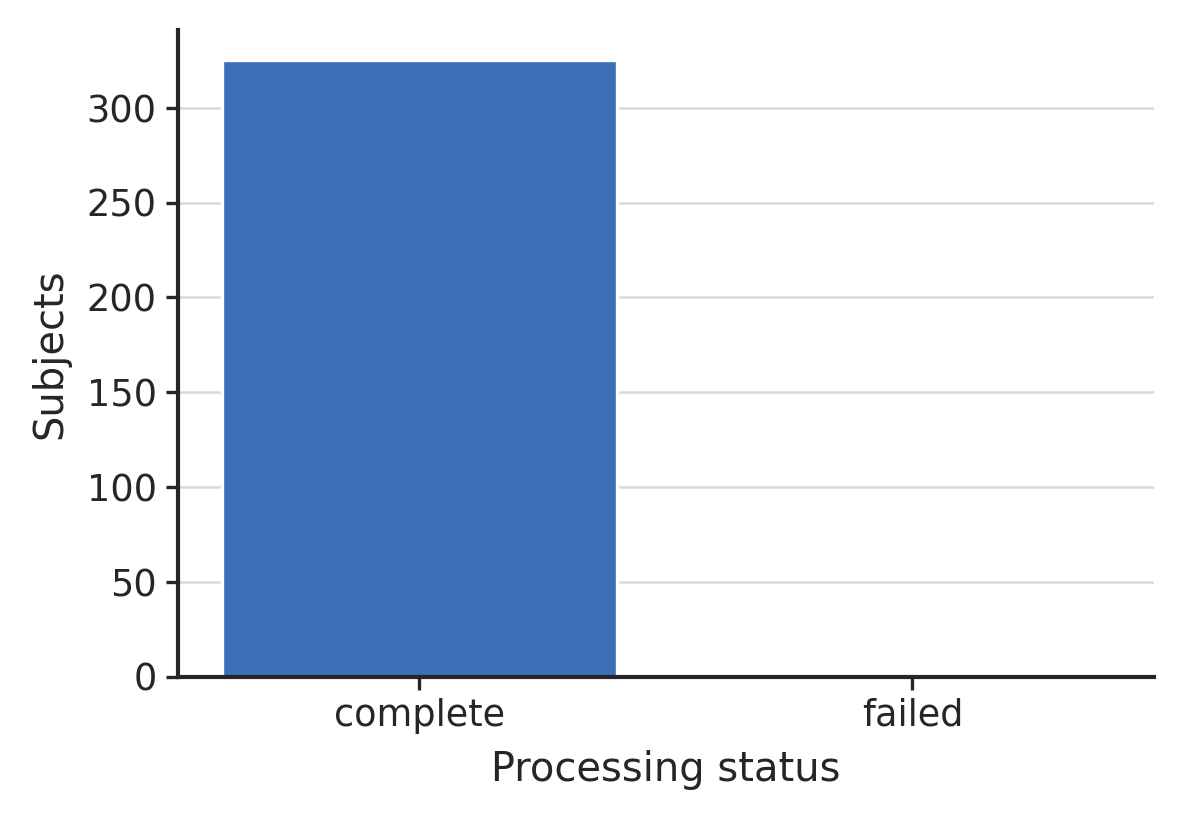

In [2]:
table('status_counts.csv')
table('status.csv')

if READY:
    counts = status['status'].value_counts().rename_axis('status')
    fig, ax = plt.subplots(figsize=(4.2, 2.8))
    ax.bar(counts.index, counts.values, color=PALETTE['blue'])
    ax.set(xlabel='Processing status', ylabel='Subjects')
    style_axes(ax, grid=True)
    save_figure(fig, '00_cohort_completeness')

## 1. Mapping coverage and barycentric validity
Mapping coverage requires successful triangle lookup, legal source indices, finite weights in [0, 1] within tolerance, and a weight sum near one.
Geometry and final-profile coverage use a fixed **fsaverage cortex intersected with valid DK labels** mask.
Reconstruction error compares the barycentrically reconstructed point with the VTK closest point in normalized sphere coordinates. This verifies numerical implementation, not anatomical alignment.
Coverage summaries report the subject median, quartiles, minimum, and maximum.

,statistic,mapping_mask_pct,geometry_pct,final_pct
0,median,100.0,99.577163,99.370413
1,Q25,100.0,99.397757,99.077961
2,Q75,100.0,99.741896,99.576162
3,minimum,100.0,97.144515,2.392965
4,maximum,100.0,99.969654,99.909964


,hemisphere,mapping_full_pct_median,mapping_full_pct_max,weight_sum_error_max_median,weight_sum_error_max_max,reconstruction_error_max_median,reconstruction_error_max_max,zero_full_pct_median,zero_full_pct_max,zero_mask_pct_median,zero_mask_pct_max
0,lh,100.0,100.0,2.220446e-16,2.220446e-16,3.152427e-16,1.025645e-13,7.192905,8.898207,0.418131,2.518789
1,rh,100.0,100.0,2.220446e-16,2.220446e-16,3.188873e-16,3.341753e-15,7.086705,9.413948,0.402865,3.192242


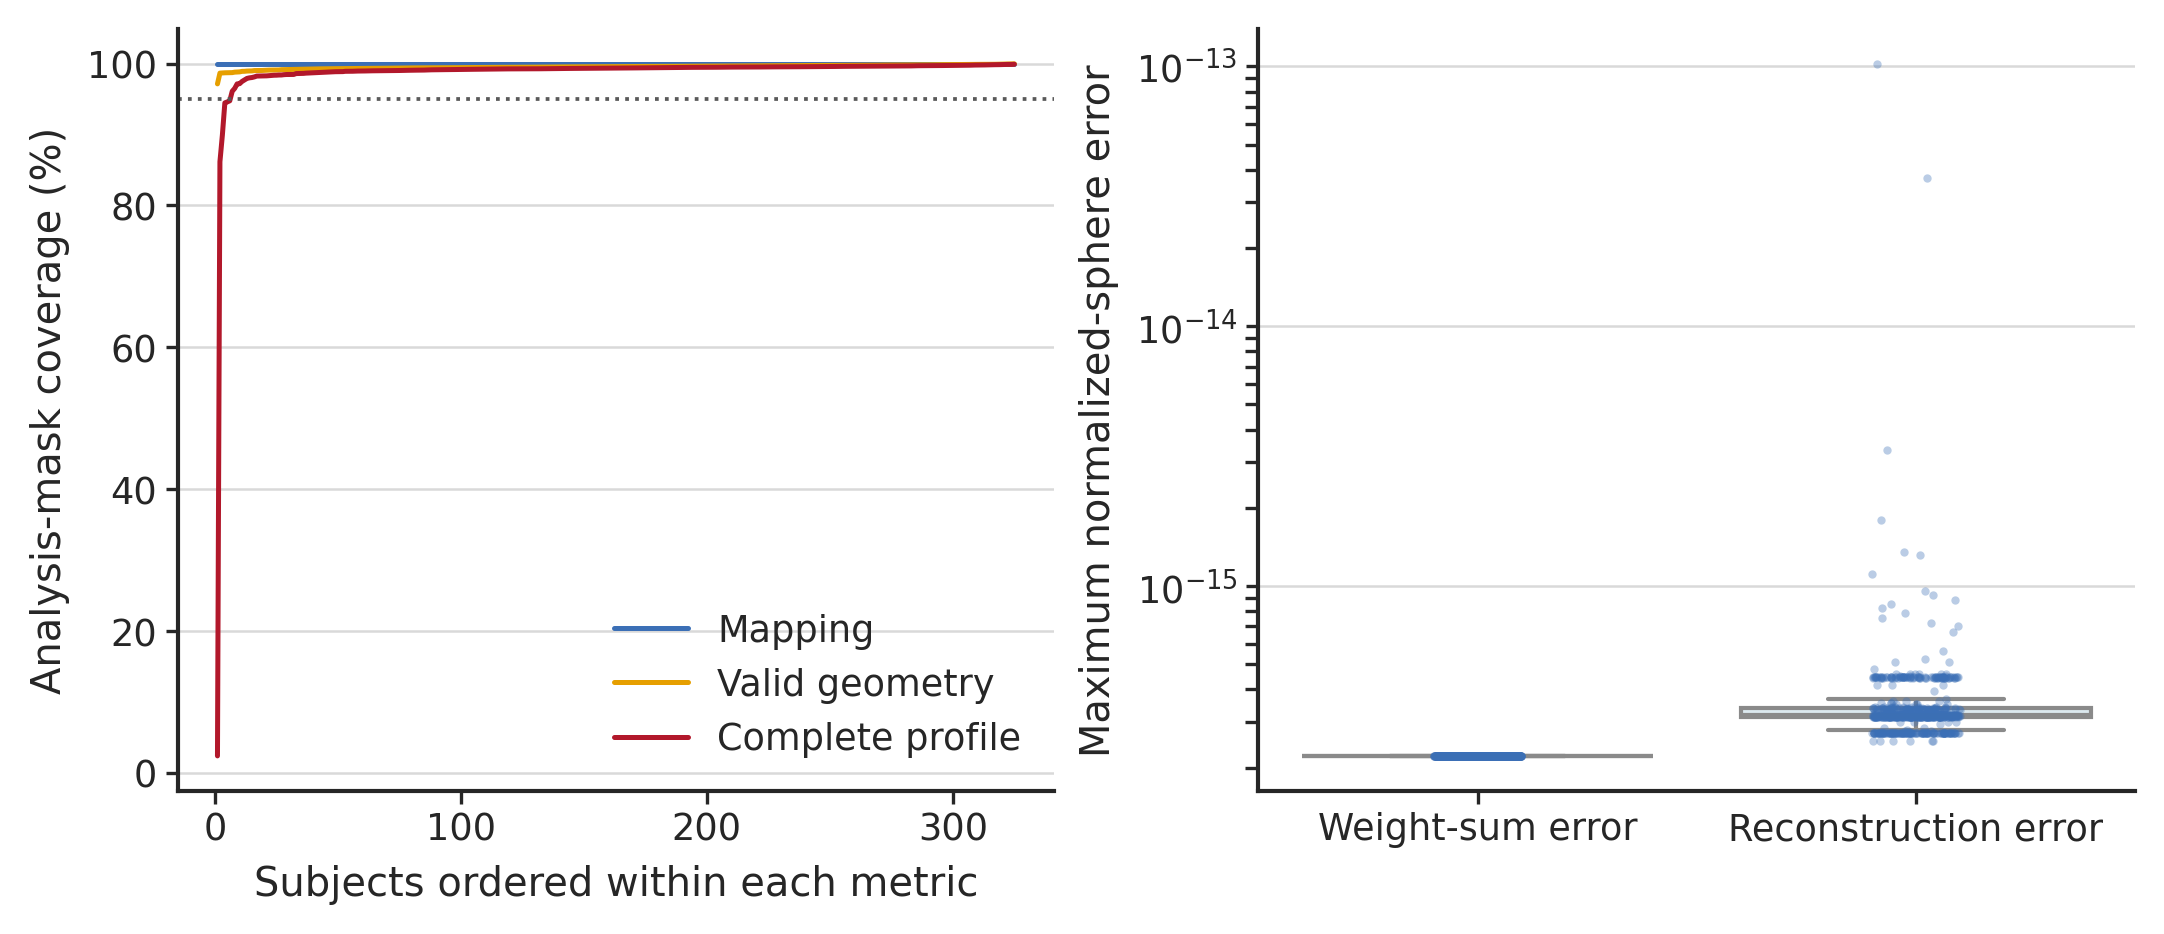

In [3]:
table('coverage_summary.csv')
table('mapping_geometry_by_hemisphere.csv')

if READY:
    fig, axes = plt.subplots(1, 2, figsize=(7.1, 3.0), constrained_layout=True)
    coverage_specs = [
        ('mapping_mask_pct', 'Mapping', PALETTE['blue']),
        ('geometry_pct', 'Valid geometry', PALETTE['orange']),
        ('final_pct', 'Complete profile', PALETTE['red']),
    ]
    for column, label, color in coverage_specs:
        values = np.sort(subject_qc[column].dropna().to_numpy())
        axes[0].plot(np.arange(1, len(values) + 1), values, label=label, color=color)
    axes[0].axhline(metadata['coverage_review_pct'], color='0.35', linestyle=':', linewidth=0.9)
    axes[0].set(xlabel='Subjects ordered within each metric', ylabel='Analysis-mask coverage (%)')
    axes[0].legend(frameon=True, facecolor="white", edgecolor="#D0D0D0", framealpha=.90, fancybox=False, fontsize=7.5, borderpad=.35, labelspacing=.35, handlelength=1.8, handletextpad=.5)

    numerical = hemisphere_qc[[
        'weight_sum_error_max', 'reconstruction_error_max'
    ]].rename(columns={
        'weight_sum_error_max': 'Weight-sum error',
        'reconstruction_error_max': 'Reconstruction error',
    }).melt(var_name='metric', value_name='maximum_error')
    numerical['maximum_error'] = numerical['maximum_error'].clip(lower=np.finfo(float).tiny)
    sns.boxplot(data=numerical, x='metric', y='maximum_error', color='#D9EAF2', showfliers=False, ax=axes[1])
    sns.stripplot(data=numerical, x='metric', y='maximum_error', color=PALETTE['blue'], size=2, alpha=0.35, ax=axes[1])
    axes[1].set_yscale('log')
    axes[1].set(xlabel='', ylabel='Maximum normalized-sphere error')
    for ax in axes:
        style_axes(ax, grid=True)
    save_figure(fig, '01_mapping_coverage_and_validity')

## 2. Column geometry consistency
Zero-length columns have coincident or nearly coincident interpolated pial and white endpoints. Full-mesh and analysis-mask results are reported separately.
Length is the straight-line endpoint distance; FreeSurfer thickness is interpolated using the same barycentric weights. Pearson and Spearman correlations, MAE, median difference, and length/thickness ratio measure internal geometric consistency. They do not independently establish cross-subject alignment.

,statistic,pearson_r,spearman_rho,mae_mm,median_difference_mm,median_length_thickness_ratio
0,median,0.962120,0.947037,0.309662,0.222655,1.091337
1,Q25,0.959470,0.943166,0.287755,0.207138,1.084382
2,Q75,0.964823,0.950856,0.328210,0.240128,1.096505
3,minimum,0.940546,0.927410,0.242767,0.157037,1.068765
4,maximum,0.970897,0.968200,0.735082,0.551142,1.225163


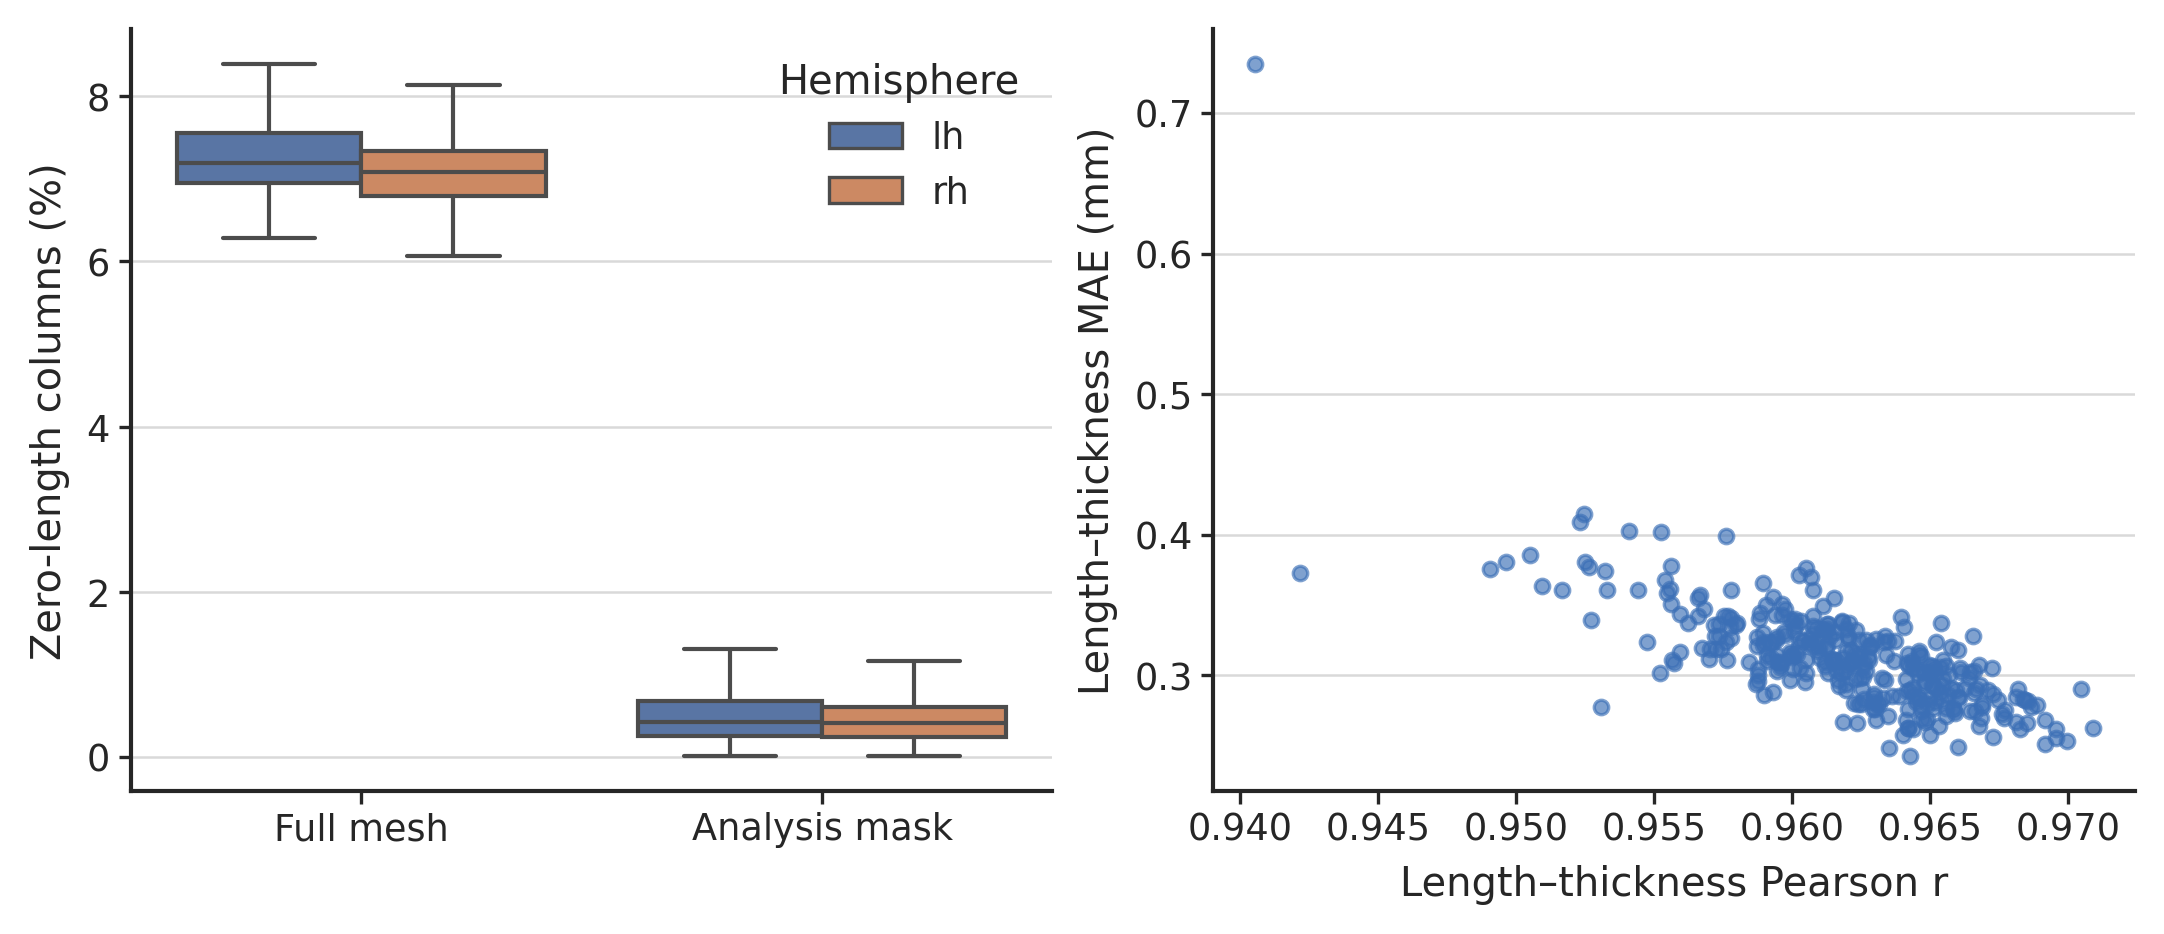

In [4]:
table('geometry_summary.csv')

if READY:
    zero = hemisphere_qc[[
        'subject_id', 'hemisphere', 'zero_full_pct', 'zero_mask_pct'
    ]].melt(
        id_vars=['subject_id', 'hemisphere'],
        var_name='surface_scope', value_name='zero_length_pct',
    )
    zero['surface_scope'] = zero['surface_scope'].map({
        'zero_full_pct': 'Full mesh',
        'zero_mask_pct': 'Analysis mask',
    })
    fig, axes = plt.subplots(1, 2, figsize=(7.1, 3.0), constrained_layout=True)
    sns.boxplot(data=zero, x='surface_scope', y='zero_length_pct', hue='hemisphere', showfliers=False, ax=axes[0])
    axes[0].set(xlabel='', ylabel='Zero-length columns (%)')
    axes[0].legend(title='Hemisphere', frameon=True, facecolor="white", edgecolor="#D0D0D0", framealpha=.90, fancybox=False, fontsize=7.5, borderpad=.35, labelspacing=.35, handlelength=1.8, handletextpad=.5)
    axes[1].scatter(subject_qc['pearson_r'], subject_qc['mae_mm'], s=12, color=PALETTE['blue'], alpha=0.65)
    axes[1].set(xlabel='Length–thickness Pearson r', ylabel='Length–thickness MAE (mm)')
    for ax in axes:
        style_axes(ax, grid=True)
    save_figure(fig, '02_column_geometry')

## 3. T1 to DWI registration QC
BBR cost outliers use an absolute robust z score above 3.5 as a review flag, not automatic exclusion. Missing cost, unreviewed registration, and unmeasured GM/WM boundary offsets remain explicit.
Manual review can be supplied in `registration_manual_review.csv` in the results directory before rerunning the script, with `subject_id`, `visual_qc_status`, `exclusion_reason`, and `gm_wm_boundary_offset_mm` columns. Exclusion requires status `exclude` and a nonempty reason.
Cost-ranked low, median, and high examples are not visual-quality classifications. Saved MD overlays show pial and white endpoints in DWI voxel coordinates and supplement full three-dimensional review.

,subject_id,bbregister_mincost,mean_white_signal,mean_gray_signal,percent_contrast,registration_error,robust_z,cost_review_flag,visual_qc_status,exclusion_reason,gm_wm_boundary_offset_mm,excluded
0,D0007,0.268341,1.646322e+08,1.840381e+08,10.817501,NaN,4.172225,True,not_reviewed,NaN,NaN,False
1,D0029,0.177209,1.453383e+08,1.692234e+08,14.899711,NaN,1.548168,False,not_reviewed,NaN,NaN,False
2,D0049,0.156530,1.654403e+08,1.952078e+08,16.623016,NaN,0.952737,False,not_reviewed,NaN,NaN,False
3,D0050,0.098552,1.634652e+08,2.004524e+08,20.043449,NaN,-0.716683,False,not_reviewed,NaN,NaN,False
4,D0051,0.170800,1.629713e+08,1.908797e+08,15.454833,NaN,1.363627,False,not_reviewed,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...
320,D0443,0.119748,1.460496e+08,1.763345e+08,18.536002,NaN,-0.106365,False,not_reviewed,NaN,NaN,False
321,D0445,0.200226,1.481277e+08,1.725047e+08,15.005352,NaN,2.210920,False,not_reviewed,NaN,NaN,False
322,D0449,0.133441,1.607730e+08,1.967325e+08,20.128635,NaN,0.287911,False,not_reviewed,NaN,NaN,False
323,D0454,0.199524,1.554189e+08,1.808663e+08,14.871920,NaN,2.190707,False,not_reviewed,NaN,NaN,False


,subject_id,bbregister_mincost,mean_white_signal,mean_gray_signal,percent_contrast,registration_error,robust_z,cost_review_flag,visual_qc_status,exclusion_reason,gm_wm_boundary_offset_mm,excluded
0,D0007,0.268341,1.646322e+08,1.840381e+08,10.817501,NaN,4.172225,True,not_reviewed,NaN,NaN,False
1,D0029,0.177209,1.453383e+08,1.692234e+08,14.899711,NaN,1.548168,False,not_reviewed,NaN,NaN,False
2,D0049,0.156530,1.654403e+08,1.952078e+08,16.623016,NaN,0.952737,False,not_reviewed,NaN,NaN,False
3,D0050,0.098552,1.634652e+08,2.004524e+08,20.043449,NaN,-0.716683,False,not_reviewed,NaN,NaN,False
4,D0051,0.170800,1.629713e+08,1.908797e+08,15.454833,NaN,1.363627,False,not_reviewed,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...
320,D0443,0.119748,1.460496e+08,1.763345e+08,18.536002,NaN,-0.106365,False,not_reviewed,NaN,NaN,False
321,D0445,0.200226,1.481277e+08,1.725047e+08,15.005352,NaN,2.210920,False,not_reviewed,NaN,NaN,False
322,D0449,0.133441,1.607730e+08,1.967325e+08,20.128635,NaN,0.287911,False,not_reviewed,NaN,NaN,False
323,D0454,0.199524,1.554189e+08,1.808663e+08,14.871920,NaN,2.190707,False,not_reviewed,NaN,NaN,False


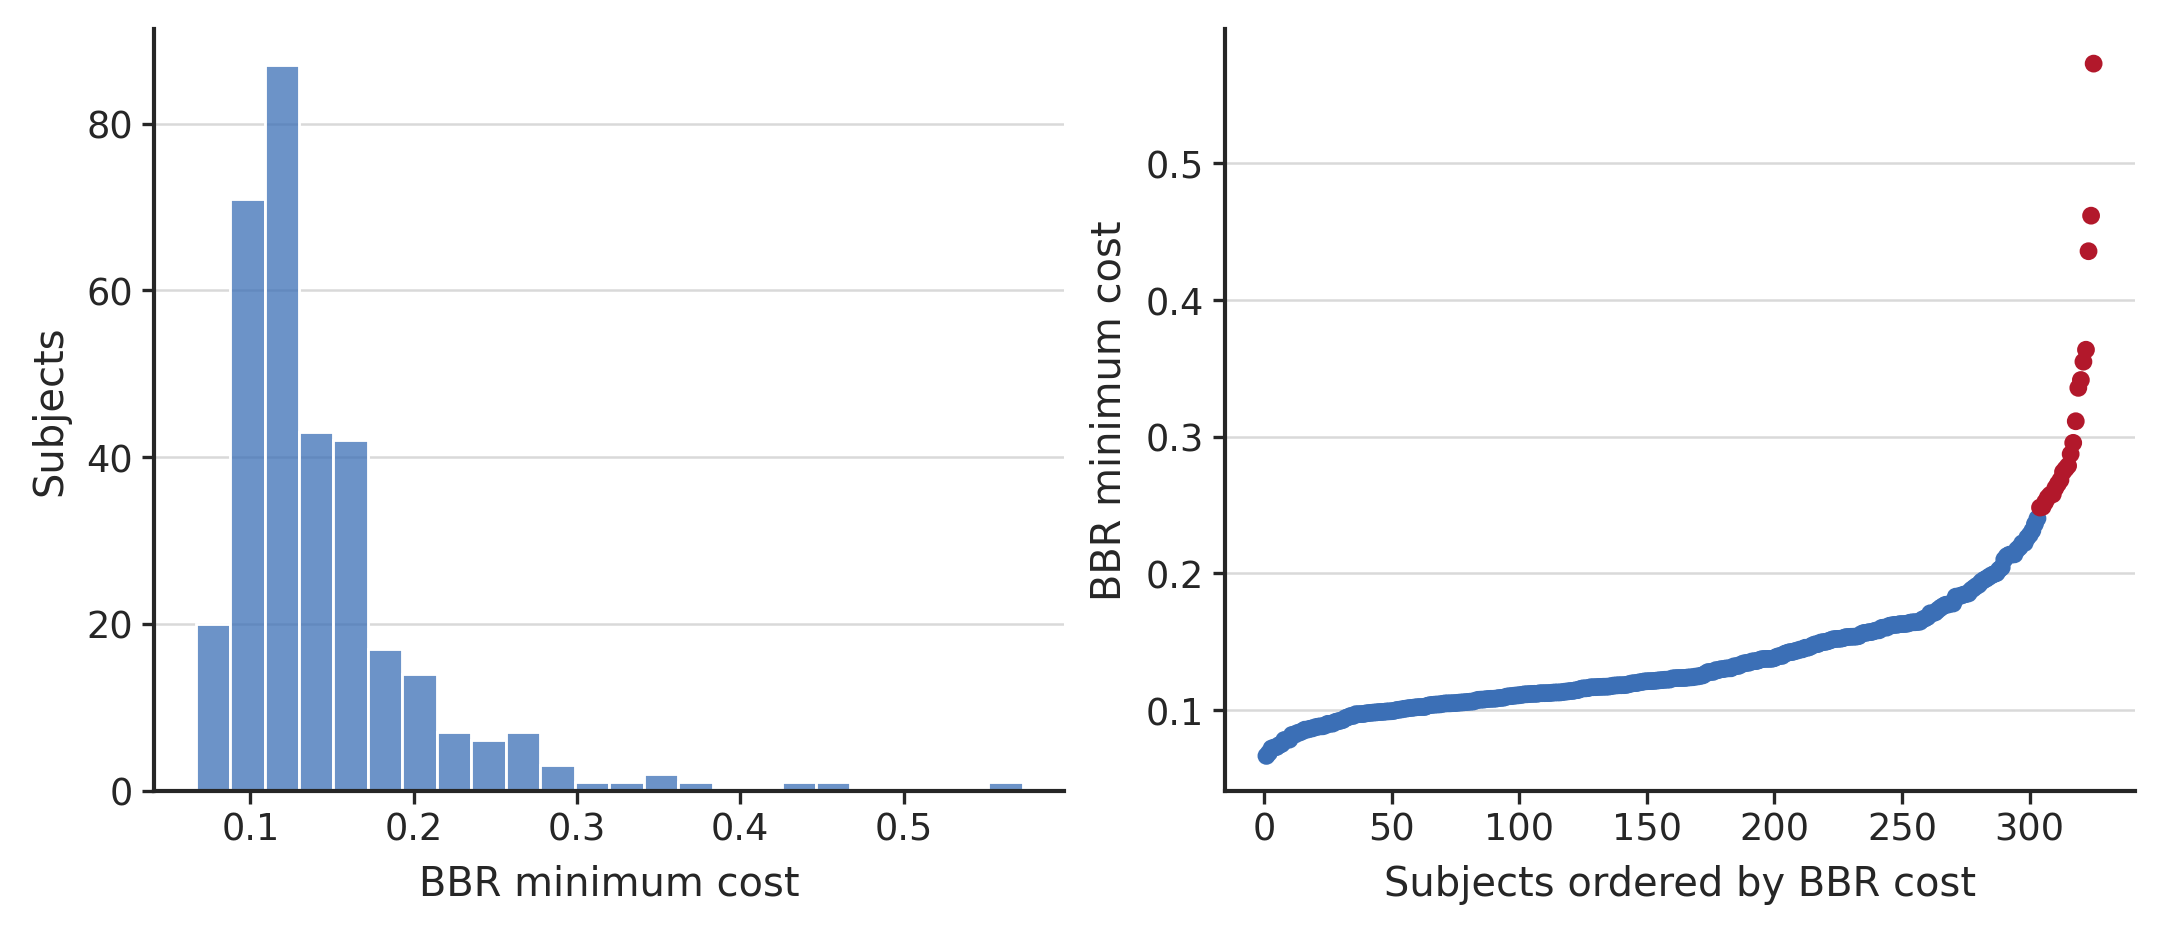

In [5]:
table('registration_qc.csv')
table('registration_review_queue.csv')

if READY:
    valid_registration = registration_qc.dropna(subset=['bbregister_mincost']).copy()
    ordered = valid_registration.sort_values('bbregister_mincost').reset_index(drop=True)
    colors = np.where(ordered['cost_review_flag'], PALETTE['red'], PALETTE['blue'])
    fig, axes = plt.subplots(1, 2, figsize=(7.1, 3.0), constrained_layout=True)
    sns.histplot(data=valid_registration, x='bbregister_mincost', bins=24, color=PALETTE['blue'], ax=axes[0])
    axes[0].set(xlabel='BBR minimum cost', ylabel='Subjects')
    axes[1].scatter(np.arange(1, len(ordered) + 1), ordered['bbregister_mincost'], c=colors, s=12)
    axes[1].set(xlabel='Subjects ordered by BBR cost', ylabel='BBR minimum cost')
    for ax in axes:
        style_axes(ax, grid=True)
    save_figure(fig, '03_registration_cost')

for name in metadata.get('figures', []):
    if name.startswith('option3_registration_overlay_'):
        show_figure(name)

## 4. Sampling validity
DWI-coordinate OOB means a transformed coordinate is below zero or above the corresponding image dimension minus one. It is distinct from illegal mapping indices and in-image zero or nonfinite MD.
A column is rejected if any of its 21 samples is OOB, nonfinite, or exactly zero; valid mapping and nonzero finite geometry are also required. Point invalidity and column exclusion rates are separate quantities. Increased pial invalidity does not by itself establish OOB as the cause.
The coverage review threshold is configurable and does not automatically exclude subjects.

,statistic,point_invalid_pct,column_invalid_pct,geometry_pct,final_pct
0,median,NaN,0.099373,99.577163,99.370413
1,Q25,NaN,0.025010,99.397757,99.077961
2,Q75,NaN,0.313460,99.741896,99.576162
3,minimum,NaN,0.000000,97.144515,2.392965
4,maximum,NaN,97.473981,99.969654,99.909964


,subject_id,status,reason,mapping_mask_pct,geometry_pct,final_pct,zero_mask_pct,column_invalid_pct,pearson_r,spearman_rho,...,mean_white_signal,mean_gray_signal,percent_contrast,registration_error,robust_z,cost_review_flag,visual_qc_status,exclusion_reason,gm_wm_boundary_offset_mm,excluded
0,D0388,complete,NaN,100.0,99.866946,2.392965,0.133054,97.473981,0.952720,0.948037,...,8.648187e+07,1.578813e+08,66.113166,NaN,6.666047,True,not_reviewed,NaN,NaN,False
1,D0222,complete,NaN,100.0,99.912965,86.162085,0.087035,13.750880,0.964119,0.947330,...,1.424404e+08,1.746427e+08,19.936397,NaN,-0.035014,False,not_reviewed,NaN,NaN,False
2,D0094,complete,NaN,100.0,99.574829,89.946945,0.425171,9.627883,0.959985,0.943483,...,1.536492e+08,1.775146e+08,14.260940,NaN,1.476903,False,not_reviewed,NaN,NaN,False
3,D0209,complete,NaN,100.0,99.592502,94.466435,0.407498,5.126068,0.961179,0.945563,...,1.446134e+08,1.839475e+08,23.603566,NaN,-1.027112,False,not_reviewed,NaN,NaN,False
4,D0279,complete,NaN,100.0,99.759903,94.600822,0.240097,5.159081,0.964106,0.957093,...,1.468623e+08,1.680281e+08,13.132311,NaN,1.175516,False,not_reviewed,NaN,NaN,False


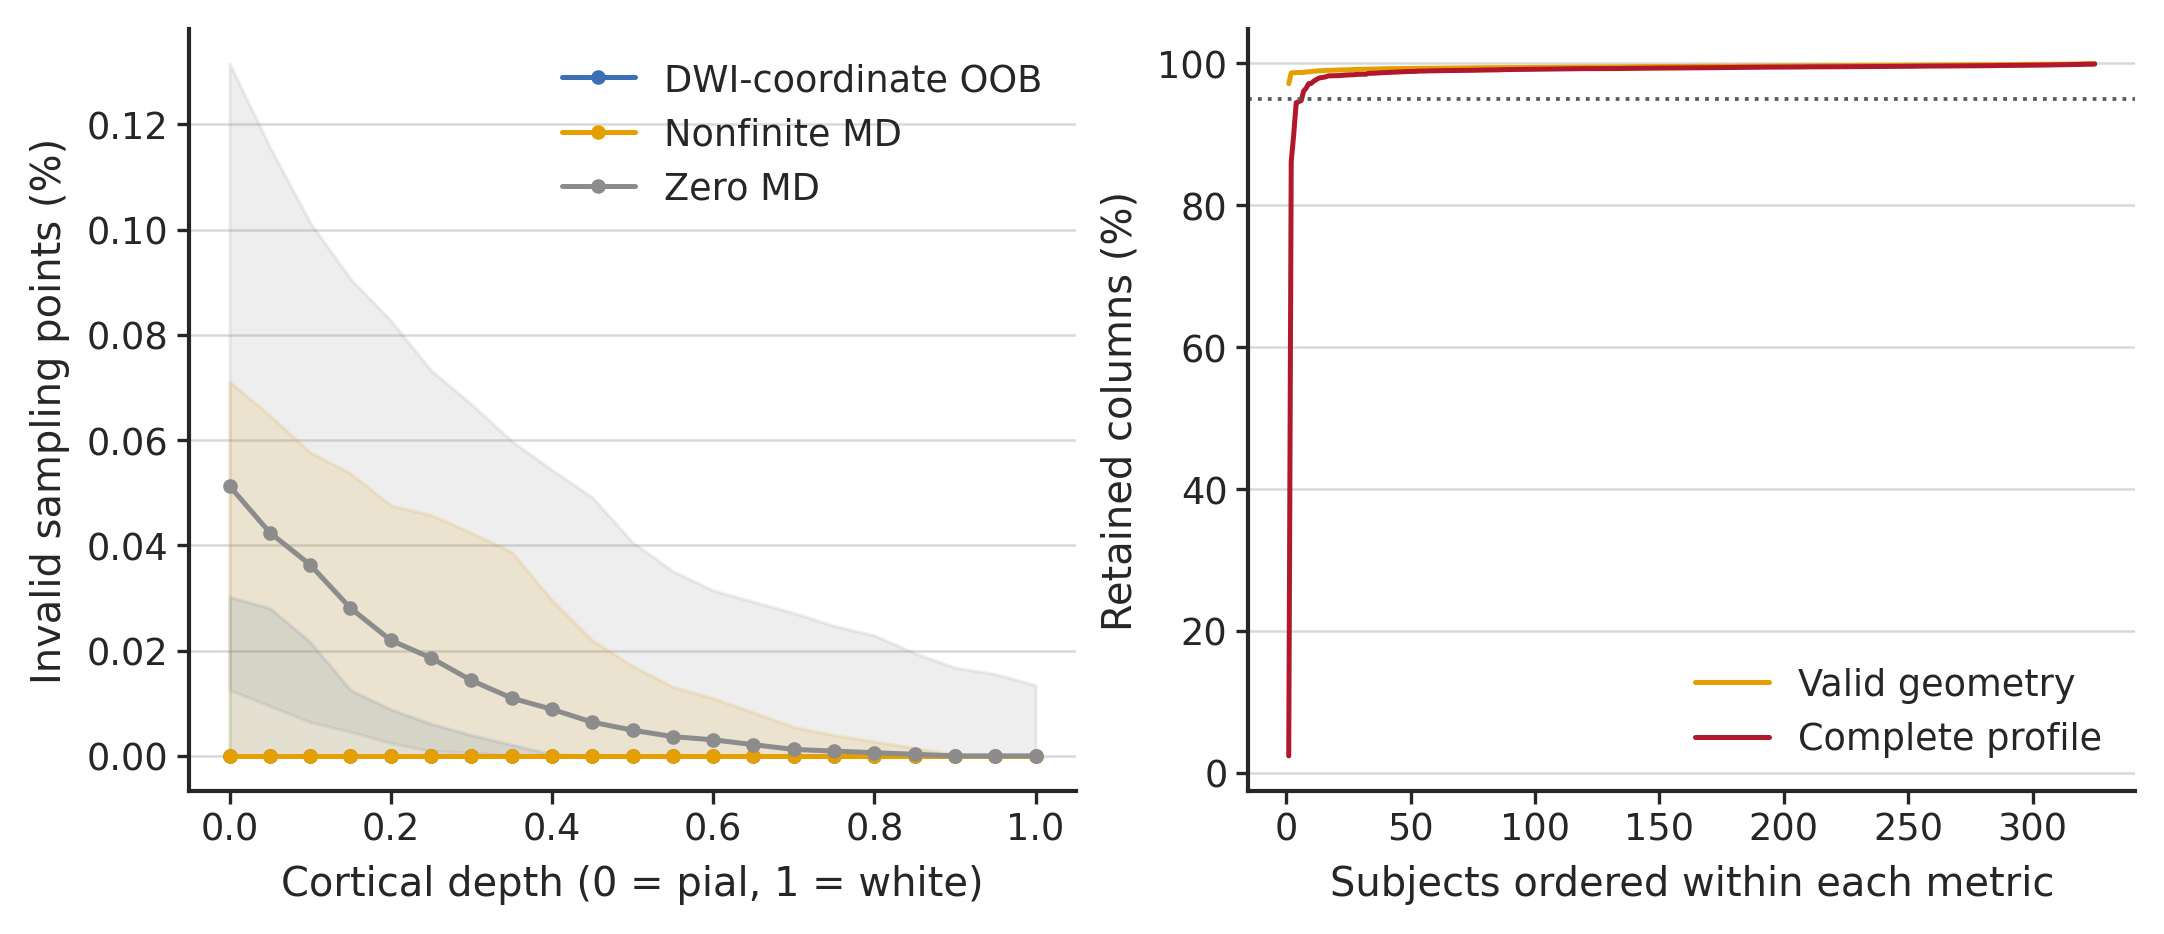

In [6]:
table('sampling_summary.csv')
table('lowest_coverage_subjects.csv')

if READY:
    fig, axes = plt.subplots(1, 2, figsize=(7.1, 3.0), constrained_layout=True)
    depth_specs = [
        ('oob_pct', 'DWI-coordinate OOB', PALETTE['blue']),
        ('nonfinite_pct', 'Nonfinite MD', PALETTE['orange']),
        ('zero_pct', 'Zero MD', PALETTE['gray']),
    ]
    for column, label, color in depth_specs:
        grouped = depth_qc.groupby('depth')[column]
        median = grouped.median()
        q25 = grouped.quantile(0.25)
        q75 = grouped.quantile(0.75)
        axes[0].plot(median.index, median, color=color, marker='o', markersize=2.5, label=label)
        axes[0].fill_between(median.index, q25, q75, color=color, alpha=0.14)
    axes[0].set(xlabel='Cortical depth (0 = pial, 1 = white)', ylabel='Invalid sampling points (%)')
    axes[0].legend(frameon=True, facecolor="white", edgecolor="#D0D0D0", framealpha=.90, fancybox=False, fontsize=7.5, borderpad=.35, labelspacing=.35, handlelength=1.8, handletextpad=.5)

    for column, label, color in [
        ('geometry_pct', 'Valid geometry', PALETTE['orange']),
        ('final_pct', 'Complete profile', PALETTE['red']),
    ]:
        values = np.sort(subject_qc[column].dropna().to_numpy())
        axes[1].plot(np.arange(1, len(values) + 1), values, color=color, label=label)
    axes[1].axhline(metadata['coverage_review_pct'], color='0.35', linestyle=':', linewidth=0.9)
    axes[1].set(xlabel='Subjects ordered within each metric', ylabel='Retained columns (%)')
    axes[1].legend(frameon=True, facecolor="white", edgecolor="#D0D0D0", framealpha=.90, fancybox=False, fontsize=7.5, borderpad=.35, labelspacing=.35, handlelength=1.8, handletextpad=.5)
    for ax in axes:
        style_axes(ax, grid=True)
    save_figure(fig, '04_sampling_validity')

## Supplement A. Trajectory construction
The external computation checks both hemispheres for 21 points, pial-to-white depth direction, endpoint equality, linear interpolation, and equal spacing. Only Option 3 is assessed.

In [7]:
table('trajectory_summary.csv')

,hemisphere,endpoint_pial_error_mm,endpoint_white_error_mm,line_error_mm,equal_spacing_error_mm
0,lh,0.0,0.0,0.0,NaN
1,rh,0.0,0.0,0.0,NaN


## Supplement B. Native source-triangle label agreement
A mixed triangle has differing native labels at its three source vertices. The final column retains its unique fsaverage template label; mixed triangles are not automatically excluded.
Boundary proximity is measured in template mesh edge hops. It is not a native-surface geodesic distance in millimeters. All-different triangles have no unique majority label.

,subject_id,hemisphere,same_label_pct,mixed_pct,majority_agreement_pct,mixed_near_template_boundary_pct
0,D0007,lh,88.435200,3.482013,NaN,40.823839
1,D0007,rh,88.727555,3.524127,NaN,33.010045
2,D0029,lh,89.412971,3.316610,NaN,18.807508
3,D0029,rh,89.351326,3.411213,NaN,25.228127
4,D0049,lh,89.349495,3.309286,NaN,24.603467
...,...,...,...,...,...,...
645,D0449,rh,89.257333,3.520465,NaN,20.353675
646,D0454,lh,88.963758,3.525958,NaN,47.377532
647,D0454,rh,89.239023,3.508868,NaN,35.380066
648,D0458,lh,89.577764,3.442951,NaN,37.493352


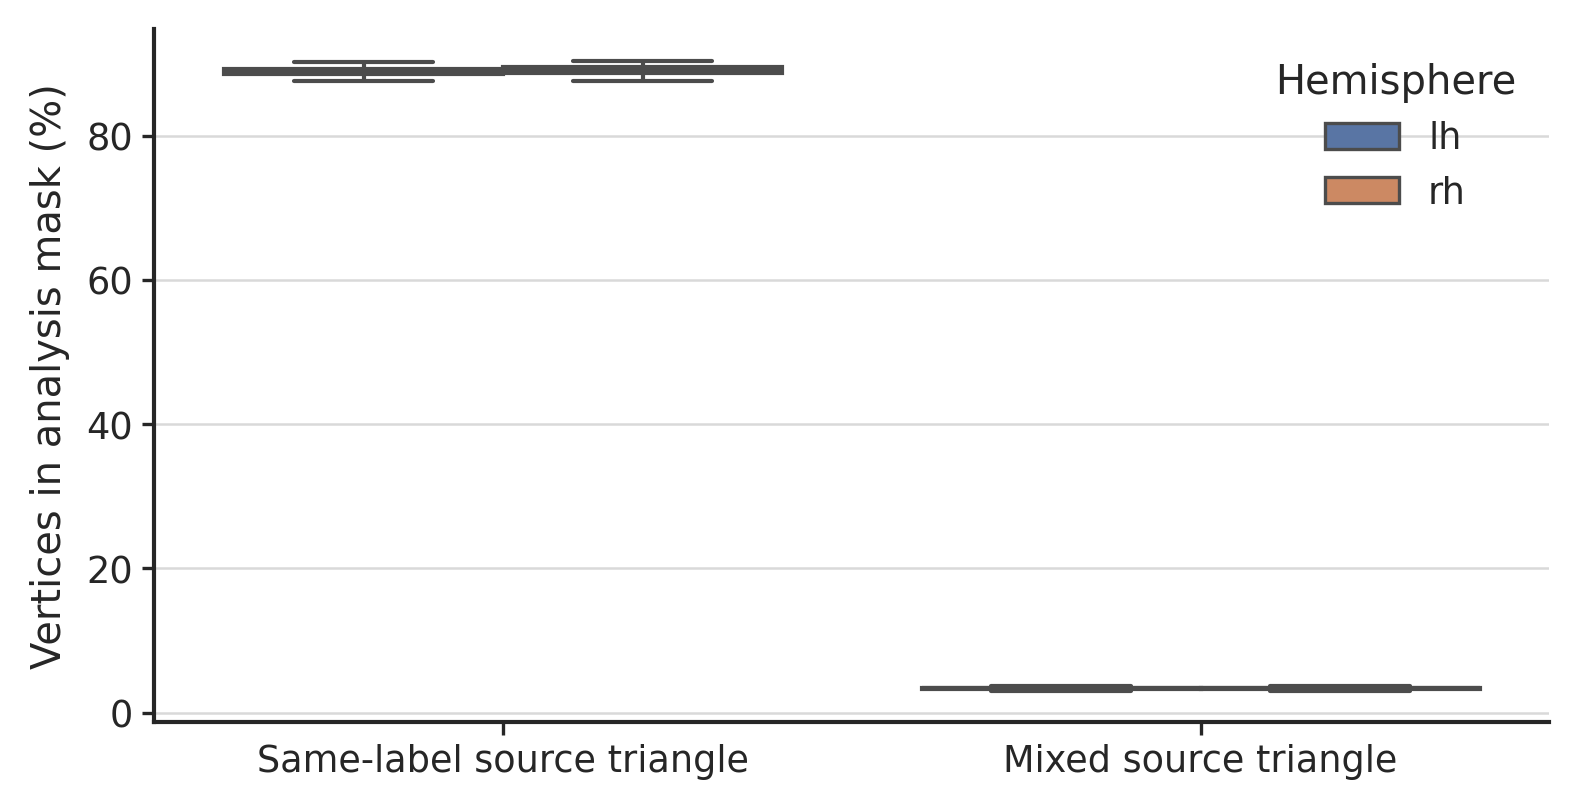

In [8]:
table('label_qc.csv')

if READY:
    label_plot = label_qc.melt(
        id_vars=['subject_id', 'hemisphere'],
        value_vars=['same_label_pct', 'mixed_pct'],
        var_name='metric', value_name='percentage',
    )
    label_plot['metric'] = label_plot['metric'].map({
        'same_label_pct': 'Same-label source triangle',
        'mixed_pct': 'Mixed source triangle',
    })
    fig, ax = plt.subplots(figsize=(6.0, 3.0))
    sns.boxplot(data=label_plot, x='metric', y='percentage', hue='hemisphere', showfliers=False, ax=ax)
    ax.set(xlabel='', ylabel='Vertices in analysis mask (%)')
    ax.legend(title='Hemisphere', frameon=True, facecolor="white", edgecolor="#D0D0D0", framealpha=.90, fancybox=False, fontsize=7.5, borderpad=.35, labelspacing=.35, handlelength=1.8, handletextpad=.5)
    style_axes(ax, grid=True)
    save_figure(fig, '05_source_triangle_label_agreement')

## Supplement C. Precomputed spatial maps
Surface-level maps are generated by the external script because they require the original column arrays and fsaverage surfaces. The summary plots above are generated transparently in this notebook from cached CSV tables.
Spatial maps show zero-length columns before and after masking, failed mapping, invalid final profiles, and length minus thickness. Projections are not full surface renderings.

In [9]:
for name in metadata.get('figures', []):
    if name.startswith('option3_spatial_qc_'):
        show_figure(name)

## Supplement D. Subject-level QC and hemisphere differences
Subject-level records preserve explicit failure, review, and exclusion states. Covariate associations are exploratory and require actual age, diagnosis, and scan-protocol metadata supplied to the external script; missing metadata are not inferred.

In [10]:
table('subject_qc.csv')
for metric in ['final_pct', 'geometry_pct', 'zero_mask_pct']:
    print(f'Left minus right: {metric}')
    table(f'hemisphere_difference_{metric}.csv')

,subject_id,status,reason,mapping_mask_pct,geometry_pct,final_pct,zero_mask_pct,column_invalid_pct,pearson_r,spearman_rho,...,mean_white_signal,mean_gray_signal,percent_contrast,registration_error,robust_z,cost_review_flag,visual_qc_status,exclusion_reason,gm_wm_boundary_offset_mm,excluded
0,D0007,complete,NaN,100.0,99.596837,99.511470,0.403163,0.085368,0.955637,0.942392,...,1.646322e+08,1.840381e+08,10.817501,NaN,4.172225,True,not_reviewed,NaN,NaN,False
1,D0029,complete,NaN,100.0,99.252365,98.125577,0.747635,1.126788,0.958991,0.955833,...,1.453383e+08,1.692234e+08,14.899711,NaN,1.548168,False,not_reviewed,NaN,NaN,False
2,D0049,complete,NaN,100.0,99.681872,99.511136,0.318128,0.170736,0.966778,0.954140,...,1.654403e+08,1.952078e+08,16.623016,NaN,0.952737,False,not_reviewed,NaN,NaN,False
3,D0050,complete,NaN,100.0,99.657529,99.606841,0.342471,0.050687,0.964819,0.944489,...,1.634652e+08,2.004524e+08,20.043449,NaN,-0.716683,False,not_reviewed,NaN,NaN,False
4,D0051,complete,NaN,100.0,98.917563,98.861207,1.082437,0.056356,0.960597,0.946079,...,1.629713e+08,1.908797e+08,15.454833,NaN,1.363627,False,not_reviewed,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
322,D0443,complete,NaN,100.0,99.716219,99.713885,0.283781,0.002334,0.962839,0.948276,...,1.460496e+08,1.763345e+08,18.536002,NaN,-0.106365,False,not_reviewed,NaN,NaN,False
323,D0445,complete,NaN,100.0,99.459115,99.225021,0.540885,0.234094,0.963604,0.948310,...,1.481277e+08,1.725047e+08,15.005352,NaN,2.210920,False,not_reviewed,NaN,NaN,False
324,D0449,complete,NaN,100.0,99.241027,99.241027,0.758973,0.000000,0.955392,0.936292,...,1.607730e+08,1.967325e+08,20.128635,NaN,0.287911,False,not_reviewed,NaN,NaN,False
325,D0454,complete,NaN,100.0,99.677870,99.677203,0.322130,0.000667,0.950501,0.927410,...,1.554189e+08,1.808663e+08,14.871920,NaN,2.190707,False,not_reviewed,NaN,NaN,False


Left minus right: final_pct


,statistic,final_pct_lh_minus_rh
0,count,325.000000
1,mean,-0.083705
2,std,0.651861
3,min,-3.377057
4,25%,-0.294056
5,50%,-0.057816
6,75%,0.104827
7,max,8.090207


Left minus right: geometry_pct


,statistic,geometry_pct_lh_minus_rh
0,count,325.000000
1,mean,-0.030989
2,std,0.242323
3,min,-0.912238
4,25%,-0.167383
5,50%,-0.021298
6,75%,0.110081
7,max,0.724424


Left minus right: zero_mask_pct


,statistic,zero_mask_pct_lh_minus_rh
0,count,325.000000
1,mean,0.030989
2,std,0.242323
3,min,-0.724424
4,25%,-0.110081
5,50%,0.021298
6,75%,0.167383
7,max,0.912238
